# Foundation models as summary backbones

_Author: Stefan T. Radev_

Amortized inference tries to solve two problems at the same time: representation learning and inference. A foundation model can be used as a plug-in solution for the former, which leaves us with the inference problem. This notebook demonstrates how to use embeddings from pre-trained foundation models as part of BayesFlow workflows:

![Example workflow with foundation models as summaries](misc/foundation/embedding_workflow.png)

We will do this twice: TabPFN for nonlinear regression, then Chronos-Bolt for a short multivariate time series. We will precompute the embeddings and use **offline** learning to avoid active calls to the frozer encoder during training.

An embedding from a pretrained foundation model need not be sufficient for the parameters we care about. We can only learn a posterior conditional on the retained representation, which may be less informative than the full data or specialized summaries. Thus, another approach is to fine-tune (parts of) the encoder for the estimation tast at hand (not explored here). Lets see how this maps onto our bayesflow terminology:

## Where does the backbone fit?

| Approach | BayesFlow input | What is trained? | Main tradeoff |
|---|---|---|---|
| Offline, frozen encoder | Cached vectors as `inference_conditions` | Inference network | Fast repeated training; a fixed simulation bank and extra storage. |
| Online, frozen encoder | Raw `summary_variables` through a wrapped encoder | Inference network | Simulate during training; encode every batch. |
| Frozen encoder + projection | Cached vectors through a small `summary_network` | Projection and inference network | Adapts the representation cheaply, but cannot recover information already discarded. |
| Partial fine-tuning | Raw `summary_variables` | Selected encoder blocks or adapters, plus inference network | More flexibility; more memory and tuning. |
| Full fine-tuning | Raw `summary_variables` | Encoder and inference network | Most flexible; highest cost and risk of overfitting. |

For the projection option, route cached vectors to `summary_variables` and use a small MLP as the summary network. Our examples use the first row: `summary_network=None`.

**Match the backend for online integration.** A PyTorch encoder belongs in a BayesFlow model using the Torch backend. Thus, you should set `KERAS_BACKEND` before importing Keras or BayesFlow. Then, the encoder can become part of a small custom `SummaryNetwork` which simply calls the encoder and optionally passes its outputs through a projection layer. Fine-tuning needs a differentiable forward call; NumPy conversion and high-level embedding helpers often stop gradients. Cached NumPy embeddings can be used with any BayesFlow backend.

A frozen model still needs evaluation mode to disable dropout. For caching, use `eval()` and a no-gradient call. For fine-tuning, use training mode for the parts being optimized and keep the tensor computation intact.

## Choosing an encoder

It is the modeler's task to find the **representation before the prediction head**. Forecasts, class probabilities, and generated text are different outputs and may discard information useful for your simulator.

The following are practical starting points, checked in October 2026. Newest is not always smallest.

| Data | Models to consider | Where to get the representation |
|---|---|---|
| Tables | [TabPFN-3.5; public v2 for this demo](https://github.com/PriorLabs/TabPFN) | `get_embeddings`; pool the contextual row embeddings. |
| Time series | [Chronos-2](https://huggingface.co/amazon/chronos-2), [Chronos-Bolt tiny](https://huggingface.co/amazon/chronos-bolt-tiny) | `embed` exposes encoder states. Chronos-2 handles multivariate context; Bolt is a small univariate model. |
| Time series | [TimesFM 3.0 and 2.5](https://github.com/google-research/timesfm) | 3.0 is newer; [2.5 has a Transformers base-model API](https://huggingface.co/docs/transformers/model_doc/timesfm2_5) returning hidden states. |
| Time series | [MOMENT](https://github.com/moment-timeseries-foundation-model/moment), [IBM Granite TTM](https://huggingface.co/collections/ibm-granite/granite-time-series) | Embedding task or backbone hidden states; check channel pooling. |
| Images | [DINOv3](https://huggingface.co/docs/transformers/model_doc/dinov3) | Image processor, then the base encoder's CLS token or patch features. |
| Text | [Qwen3-Embedding](https://huggingface.co/Qwen/Qwen3-Embedding-0.6B) | Tokenizer and documented sentence embedding/pooling. |
| Audio | [CLAP](https://huggingface.co/docs/transformers/model_doc/clap) | Audio processor and audio features; match the required sample rate. |

Check the checkpoint's license and access requirements. The runnable examples use public, small checkpoints: TabPFN v2 and Chronos-Bolt tiny. Your own application may demand larger models.

### A short Hugging Face guide

`from_pretrained` downloads and caches model weights. It does not make every model an interchangeable encoder. Read the model card for preprocessing, masks, normalization, and pooling. For encoder–decoder models, select the encoder; for decoder-only models, select the hidden states before the task head.

For example, the following is an **optional TimesFM alternative**, not needed for this notebook's run. Its base-model API exposes the final patch representation directly. The input here has 128 time steps, a multiple of its 32-step patch length.

```python
from transformers import TimesFm2_5Model

encoder = TimesFm2_5Model.from_pretrained("google/timesfm-2.5-200m-transformers").eval()

with torch.inference_mode():
    output = encoder(past_values=series)  # (datasets, 128)
    embedding = output.last_hidden_state[:, -1]
    # Retain output.loc and output.scale if level or scale carry parameter information.
```

[TimesFM's documented outputs](https://huggingface.co/docs/transformers/model_doc/timesfm2_5) differ from those of a text or image encoder. Do not blindly average every axis: preserve channel identity, exclude padding, and use the model's documented pooling rule. Save the checkpoint version, preprocessing, and pooling choices with your BayesFlow estimator.

## Setup

Restart the kernel before running the notebook. Install BayesFlow from this repository (`python -m pip install -e .` at the repository root), then install the example's extra dependencies:

```python
%pip install "tabpfn==9.2.0" "chronos-forecasting==2.3.2" "transformers==5.4.0" "torch>=2.6"
```

The first run needs internet access to download the two checkpoints. Later runs reuse the model cache. The encoders use CUDA when available, as does BayesFlow's Torch backend. We use one TabPFN ensemble member. Larger simulation banks improve validation but increase the one-time embedding cost.

In [1]:
import os
os.environ["KERAS_BACKEND"] = "torch"

import numpy as np
import matplotlib.pyplot as plt
import keras
import torch
import bayesflow as bf

from tabpfn import TabPFNRegressor
from tabpfn.constants import ModelVersion

INFO:bayesflow:Using backend 'torch'
When using torch backend, we need to disable autograd by default to avoid excessive memory usage. Use

with torch.enable_grad():
    ...

in contexts where you need gradients (e.g. custom training loops).


In [2]:
rng = np.random.default_rng(2026)

device = "cuda" if torch.cuda.is_available() else "cpu"

plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "figure.dpi": 110,
    "axes.prop_cycle": plt.cycler(color=["#287D8E", "#D58B40", "#596A85"]),
})

## 1. TabPFN: nonlinear regression with unequal noise

We use the model from [Generalized linear models](Bayesian_GLM.ipynb), now with a pretrained encoder. Each dataset has 100 rows and two predictors. We keep the design matrix fixed across simulations and observations. The response has a sinusoidal effect, an interaction, and noise that increases with the second predictor:

$$y_i = b + a\sin(1.5 x_{i1}) + c x_{i1}x_{i2} + 0.5x_{i2} + \epsilon_i,$$
$$\epsilon_i \sim \mathcal N\!\left(0,\,[\exp(\ell)(1+0.4|x_{i2}|)]^2\right).$$

We infer $\theta=(b,a,c,\ell)$, where $\ell=\log\sigma$. Independent normal priors allow positive and negative effects. This is a dataset-level inference problem: TabPFN sees the observed predictors and responses, while BayesFlow learns the four-parameter posterior.

In [3]:
x = rng.uniform(-2, 2, size=(100, 2)).astype("float32")
basis = np.column_stack([np.ones(100), np.sin(1.5 * x[:, 0]), x[:, 0] * x[:, 1]])
prior_mean = np.array([0.0, 0.0, 0.0, -0.5])
prior_std = np.array([0.7, 0.8, 0.6, 0.3])


def regression_response(theta):
    mean = theta[:, :3] @ basis.T + 0.5 * x[:, 1]
    scale = np.exp(theta[:, 3:4]) * (1 + 0.4 * np.abs(x[:, 1]))
    return (mean + scale * rng.normal(size=mean.shape)).astype("float32")


def simulate_regression(n):
    theta = rng.normal(prior_mean, prior_std, size=(n, 4)).astype("float32")
    return {"theta": theta, "y": regression_response(theta)}


train_raw, val_raw, test_raw = [simulate_regression(n) for n in (2048, 256, 128)]

### Compute the frozen summaries once

[TabPFN's `fit`](https://github.com/PriorLabs/TabPFN) prepares a dataset as in-context input; it does not optimize the pretrained weights. We reuse one model, call `fit` and `get_embeddings` for each dataset, then average its row embeddings. The public embedding method returns NumPy arrays, which is exactly what we need for offline training.

TabPFN [standardizes each dataset's response](https://github.com/PriorLabs/TabPFN/blob/main/src/tabpfn/regressor.py). We append its mean and standard deviation so that location and scale information remain available. The predictors are fixed here; for varying designs, also consider information removed by predictor preprocessing.

All observed responses are legitimate conditioning data for posterior inference. We therefore use `data_source="train"` for both simulations and observations. This is different from predicting a held-out row's response.

In [ ]:
backbone = TabPFNRegressor.create_default_for_version(
    ModelVersion.V2, 
    n_estimators=1, 
    device=device,
    fit_mode="fit_preprocessors", 
    random_state=2026
)


def tabpfn_summary(responses):
    summaries = []
    for y in responses:
        backbone.fit(x, y)
        # One query row is enough: we request the 100 context (train) embeddings.
        rows = backbone.get_embeddings(x[:1], data_source="train")[0]
        summaries.append(np.r_[rows.mean(axis=0), y.mean(), y.std()])

    return np.asarray(summaries)


train, val, test = [
    {"theta": data["theta"], "embedding": tabpfn_summary(data["y"])}
    for data in (train_raw, val_raw, test_raw)
]

### Train a small inference network

`theta` becomes `inference_variables`; the cached `embedding` becomes `inference_conditions`. We use a two-layer spline coupling flow with small subnets and dropout. There is no summary network, and training only uses the cached embeddings.

BayesFlow standardizes targets and conditions using the training data. We monitor validation loss over a fixed number of epochs. Dropout is active during training, so training loss can be higher than validation loss.

In [5]:
workflow = bf.BasicWorkflow(
    inference_variables="theta",
    inference_conditions="embedding",
    summary_network=None,
    inference_network=bf.networks.CouplingFlow(
        depth=2, 
        transform="spline",
        subnet_kwargs={"widths": (128, 128), "dropout": 0.3},
    ),
    standardize="all",
    initial_learning_rate=1e-3
)

history = workflow.fit_offline(train, validation_data=val, epochs=60, batch_size=64, verbose=2)

INFO:bayesflow:Fitting on dataset instance of OfflineDataset.
INFO:bayesflow:Building on a test batch.


Epoch 1/60
32/32 - 1s - 36ms/step - loss: 5.4238 - val_loss: 4.8913
Epoch 2/60
32/32 - 1s - 33ms/step - loss: 4.7006 - val_loss: 4.1864
Epoch 3/60
32/32 - 1s - 33ms/step - loss: 4.1312 - val_loss: 3.5148
Epoch 4/60
32/32 - 1s - 33ms/step - loss: 3.7298 - val_loss: 3.1244
Epoch 5/60
32/32 - 1s - 33ms/step - loss: 3.3738 - val_loss: 2.8927
Epoch 6/60
32/32 - 1s - 33ms/step - loss: 3.1164 - val_loss: 2.6522
Epoch 7/60
32/32 - 1s - 34ms/step - loss: 2.7789 - val_loss: 2.2087
Epoch 8/60
32/32 - 1s - 33ms/step - loss: 2.5468 - val_loss: 2.1299
Epoch 9/60
32/32 - 1s - 34ms/step - loss: 2.4085 - val_loss: 2.0766
Epoch 10/60
32/32 - 1s - 33ms/step - loss: 2.4146 - val_loss: 1.8732
Epoch 11/60
32/32 - 1s - 33ms/step - loss: 2.1699 - val_loss: 1.8190
Epoch 12/60
32/32 - 1s - 33ms/step - loss: 2.0714 - val_loss: 1.6196
Epoch 13/60
32/32 - 1s - 33ms/step - loss: 1.9156 - val_loss: 1.4560
Epoch 14/60
32/32 - 1s - 33ms/step - loss: 1.8562 - val_loss: 1.5109
Epoch 15/60
32/32 - 1s - 34ms/step - loss: 

INFO:bayesflow:Training completed in 1.10 minutes.


### Loss and parameter recovery

BayesFlow's diagnostics show the training and validation losses and parameter recovery on test simulations. The recovery plot uses posterior medians and central 90% credible intervals.

INFO:bayesflow:Sampling completed in 0.08 seconds.


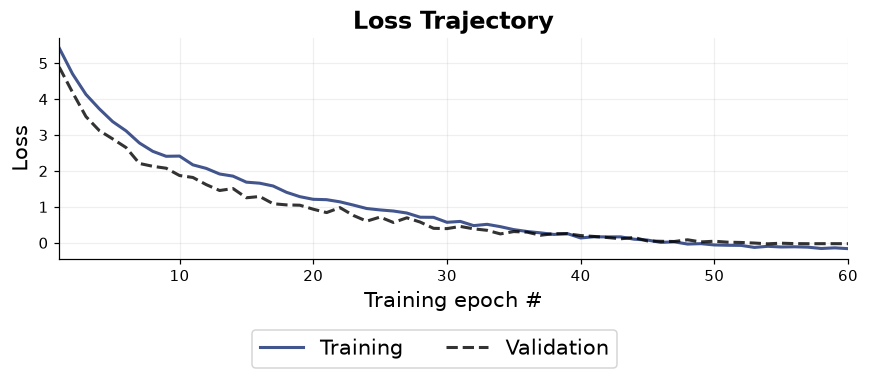

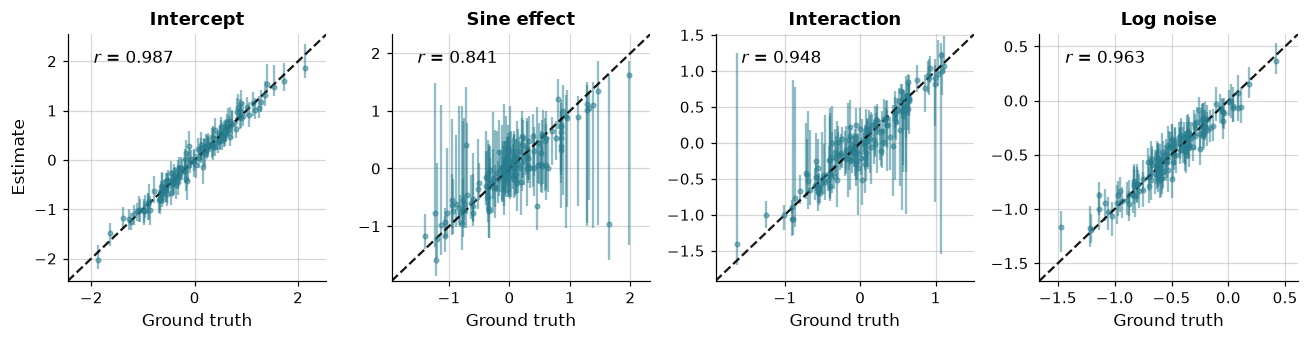

In [6]:
bf.diagnostics.loss(
    history, 
    smoothing_factor=0,
    val_marker="", 
    figsize=(8, 3.5),
)

samples = workflow.sample(conditions={"embedding": test["embedding"]}, num_samples=500)["theta"]

bf.diagnostics.recovery(
    estimates=samples, 
    targets=test["theta"],
    variable_names=["Intercept", "Sine effect", "Interaction", "Log noise"],
    uncertainty_agg_kwargs={"prob": 0.9}, color="#287D8E",
    num_col=4, 
    figsize=(12, 3.2), 
    markersize=3,
    label_fontsize=11, 
    title_fontsize=12, 
    metric_fontsize=11, 
    tick_fontsize=10,
)

### Use the same encoder on observations

Here we create one synthetic observed dataset so its true parameters are known. For real data, replace `observed_y` with the 100 observed responses on the same design. Only the embedding enters `sample`; the true parameters are used for plotting.

INFO:bayesflow:Sampling completed in 0.02 seconds.


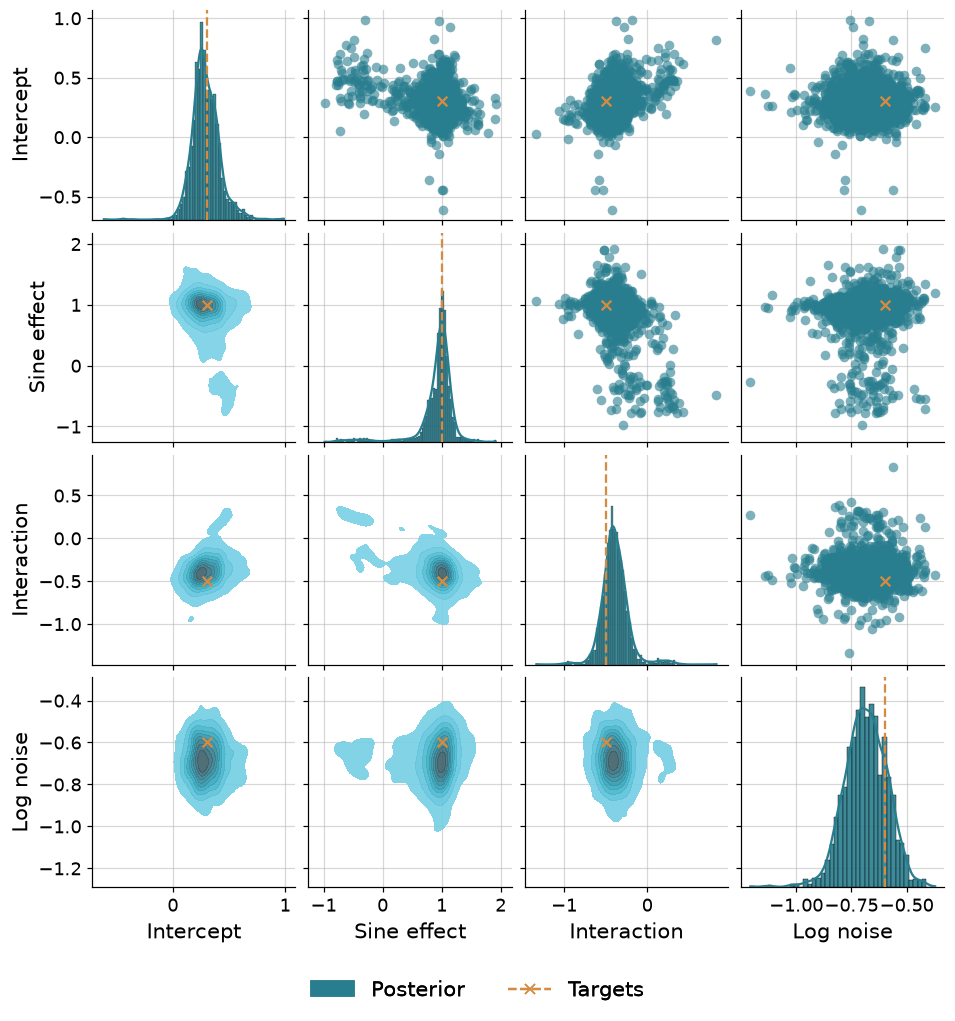

In [7]:
observed_theta = np.array([[0.3, 1.0, -0.5, -0.6]], dtype="float32")
observed_y = regression_response(observed_theta)
observed_embedding = tabpfn_summary(observed_y)
observed_samples = workflow.sample(
    conditions={"embedding": observed_embedding}, num_samples=2000,
)["theta"][0]

bf.diagnostics.pairs_posterior(
    observed_samples, targets=observed_theta[0],
    variable_names=["Intercept", "Sine effect", "Interaction", "Log noise"],
    post_color="#287D8E", target_color="#D58B40",
    height=2.2, place_legend_below=True,
);

## 2. Time series: a small frozen Chronos encoder

The same workflow works for sequences. We use [Chronos-Bolt tiny](https://huggingface.co/amazon/chronos-bolt-tiny), a 9-million-parameter model with a public `embed` method. It is smaller than TimesFM and keeps this example quick. We use its encoder to summarize each trajectory.

Our data are two coupled time series:

$$x_t = \begin{pmatrix}a & 0.15 \\ -0.10 & d\end{pmatrix}x_{t-1} + 0.4\epsilon_t,\qquad \epsilon_t\sim\mathcal N(0,I).$$

We infer the two persistence coefficients, $a,d\sim\mathcal U(-0.7,0.7)$. The coefficient matrix stays fixed within each dataset. Its maximum absolute row sum is below 0.85, so every prior draw is stable. Each dataset has exactly 128 observations after a short burn-in.

Bolt encodes one channel at a time. We concatenate the channel embeddings in a fixed order and retain the means and scales removed by its normalization. This is a useful small example, but those summaries are not guaranteed to preserve arbitrary cross-channel dynamics. For inference on a full unknown VAR matrix, [Chronos-2](https://huggingface.co/amazon/chronos-2) offers a native multivariate `embed` method.

In [8]:
def simulate_var(theta, n_steps=128, burn_in=64):
    theta = np.asarray(theta, dtype=np.float32)
    matrix = np.zeros((len(theta), 2, 2), dtype=np.float32)
    matrix[:, 0, 0], matrix[:, 1, 1] = theta.T
    matrix[:, 0, 1], matrix[:, 1, 0] = 0.15, -0.10
    state = np.zeros((len(theta), 2), dtype=np.float32)
    series = np.empty((len(theta), 2, n_steps), dtype=np.float32)
    for t in range(n_steps + burn_in):
        state = np.einsum("bij,bj->bi", matrix, state) + 0.4 * rng.normal(size=state.shape)
        if t >= burn_in:
            series[:, :, t - burn_in] = state
    return series


var_theta = rng.uniform(-0.7, 0.7, size=(4096 + 512 + 128, 2)).astype("float32")
var_series = simulate_var(var_theta)

In [9]:
from chronos import ChronosBoltPipeline

chronos = ChronosBoltPipeline.from_pretrained(
    "amazon/chronos-bolt-tiny",
    device_map=device,
    dtype=torch.float32,
)
chronos.model.eval()

ChronosBoltModelForForecasting(
  (shared): Embedding(2, 256)
  (input_patch_embedding): ResidualBlock(
    (dropout): Dropout(p=0.1, inplace=False)
    (hidden_layer): Linear(in_features=32, out_features=1024, bias=True)
    (act): ReLU()
    (output_layer): Linear(in_features=1024, out_features=256, bias=True)
    (residual_layer): Linear(in_features=32, out_features=256, bias=True)
  )
  (patch): Patch()
  (instance_norm): InstanceNorm()
  (encoder): T5Stack(
    (embed_tokens): Embedding(2, 256)
    (block): ModuleList(
      (0): T5Block(
        (layer): ModuleList(
          (0): T5LayerSelfAttention(
            (SelfAttention): T5Attention(
              (q): Linear(in_features=256, out_features=256, bias=False)
              (k): Linear(in_features=256, out_features=256, bias=False)
              (v): Linear(in_features=256, out_features=256, bias=False)
              (o): Linear(in_features=256, out_features=256, bias=False)
              (relative_attention_bias): Embedding

### Encode once, then train the inference head

`embed` returns a sequence of encoder tokens. This checkpoint puts its summary token (`[REG]`) last. We keep that token for each channel. The small loop below only limits memory use; each simulation is encoded once. BayesFlow sees a matrix of fixed embeddings and needs no summary network.

The adapter maps the bounded persistence coefficients to an unconstrained training space and maps posterior draws back to $(-0.7, 0.7)$.

In [10]:
def embed_var(series, batch_size=64):
    summaries = []
    for batch in torch.from_numpy(series).split(batch_size):
        tokens, (location, scale) = chronos.embed(batch.flatten(0, 1))
        per_channel = torch.cat([tokens[:, -1], location[:, None], scale[:, None]], dim=-1)
        summaries.append(per_channel.reshape(len(batch), -1).cpu().numpy())
    return np.concatenate(summaries).astype("float32")


var_embedding = embed_var(var_series)
var_train = {"theta": var_theta[:4096], "embedding": var_embedding[:4096]}
var_validation = {"theta": var_theta[4096:4608], "embedding": var_embedding[4096:4608]}
var_test = {"theta": var_theta[4608:], "embedding": var_embedding[4608:]}

In [11]:
var_adapter = (
    bf.Adapter().constrain("theta", lower=-0.7, upper=0.7)
    .rename("theta", "inference_variables").rename("embedding", "inference_conditions")
)

var_workflow = bf.BasicWorkflow(
    adapter=var_adapter,
    summary_network=None,
    inference_network=bf.networks.CouplingFlow(
        depth=2, 
        transform="spline",
        subnet_kwargs={"widths": [32, 32], "dropout": 0.3},
    ),
    standardize=["inference_variables", "inference_conditions"],
    initial_learning_rate=1e-3,
)

var_history = var_workflow.fit_offline(var_train, validation_data=var_validation, epochs=25, batch_size=64, verbose=2)

INFO:bayesflow:Fitting on dataset instance of OfflineDataset.
INFO:bayesflow:Building on a test batch.


Epoch 1/25
64/64 - 2s - 34ms/step - loss: 2.2276 - val_loss: 1.4989
Epoch 2/25
64/64 - 2s - 35ms/step - loss: 1.5033 - val_loss: 1.0952
Epoch 3/25
64/64 - 2s - 34ms/step - loss: 1.2613 - val_loss: 0.9133
Epoch 4/25
64/64 - 2s - 34ms/step - loss: 1.1622 - val_loss: 0.8208
Epoch 5/25
64/64 - 2s - 34ms/step - loss: 1.0355 - val_loss: 0.7016
Epoch 6/25
64/64 - 2s - 35ms/step - loss: 0.9179 - val_loss: 0.6635
Epoch 7/25
64/64 - 2s - 34ms/step - loss: 0.8354 - val_loss: 0.6005
Epoch 8/25
64/64 - 2s - 34ms/step - loss: 0.7667 - val_loss: 0.5415
Epoch 9/25
64/64 - 2s - 35ms/step - loss: 0.6944 - val_loss: 0.4925
Epoch 10/25
64/64 - 2s - 36ms/step - loss: 0.6603 - val_loss: 0.4438
Epoch 11/25
64/64 - 2s - 35ms/step - loss: 0.6141 - val_loss: 0.4300
Epoch 12/25
64/64 - 2s - 34ms/step - loss: 0.5564 - val_loss: 0.4224
Epoch 13/25
64/64 - 2s - 35ms/step - loss: 0.5013 - val_loss: 0.4308
Epoch 14/25
64/64 - 2s - 34ms/step - loss: 0.4770 - val_loss: 0.3680
Epoch 15/25
64/64 - 2s - 34ms/step - loss: 

INFO:bayesflow:Training completed in 55.75 seconds.


INFO:bayesflow:Sampling completed in 0.05 seconds.


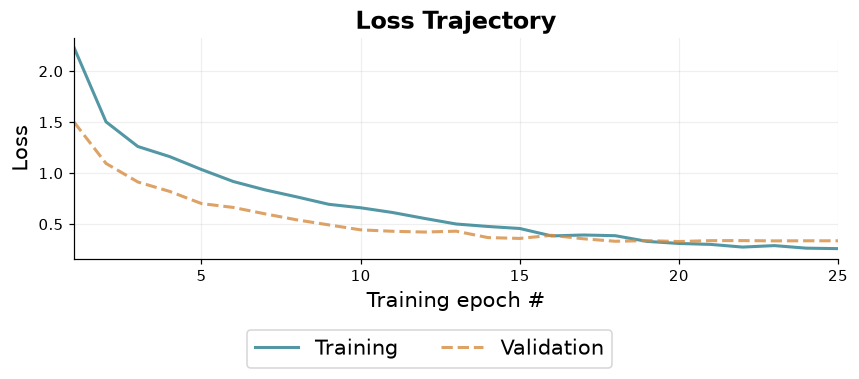

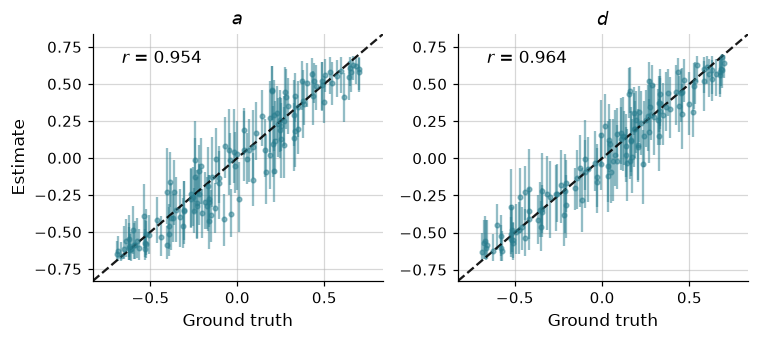

In [12]:
bf.diagnostics.loss(
    var_history, smoothing_factor=0, train_color="#287D8E", val_color="#D58B40", val_marker="", figsize=(8, 3.5)
)

var_samples = var_workflow.sample(conditions={"embedding": var_test["embedding"]}, num_samples=500)["theta"]

bf.diagnostics.recovery(
    estimates=var_samples, 
    targets=var_test["theta"], 
    variable_names=["$a$", "$d$"],
    uncertainty_agg_kwargs={"prob": 0.9}, 
    color="#287D8E",
    num_col=2, 
    figsize=(7, 3.2), 
    markersize=3,
    label_fontsize=11, 
    title_fontsize=12, 
    metric_fontsize=11, 
    tick_fontsize=10
)

### A new observed trajectory

For an observed dataset, we run the same frozen encoder once and reuse the trained inference head. Here we simulate one observation at known coefficients so that we can compare its posterior with the generating values. The training, validation, and test datasets above used independent prior draws.

INFO:bayesflow:Sampling completed in 0.02 seconds.


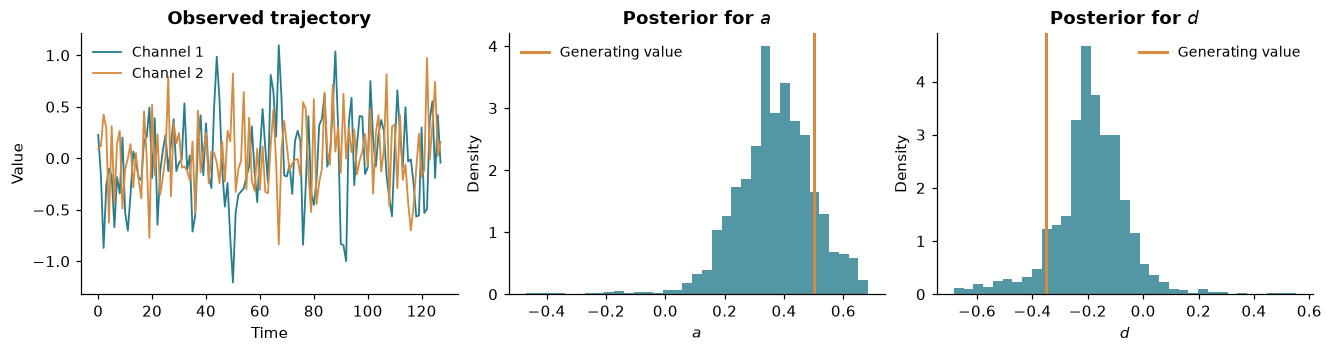

In [13]:
var_truth = np.array([[0.50, -0.35]])
var_observed = simulate_var(var_truth)

var_observed_samples = var_workflow.sample(conditions={"embedding": embed_var(var_observed)}, num_samples=2000)
var_observed_samples = var_observed_samples["theta"][0]

fig, axes = plt.subplots(1, 3, figsize=(12, 3.1), layout="constrained")
for channel, color in enumerate(["#287D8E", "#D58B40"]):
    axes[0].plot(var_observed[0, channel], color=color, lw=1.2, label=f"Channel {channel + 1}")

axes[0].set(title="Observed trajectory", xlabel="Time", ylabel="Value")
axes[0].legend(frameon=False, fontsize=9)

for j, label in enumerate(["$a$", "$d$"]):
    axes[j + 1].hist(var_observed_samples[:, j], bins=35, density=True, color="#287D8E", alpha=0.8)
    axes[j + 1].axvline(var_truth[0, j], color="#D58B40", lw=2, label="Generating value")
    axes[j + 1].set(title=f"Posterior for {label}", xlabel=label, ylabel="Density")
    axes[j + 1].legend(frameon=False, fontsize=9)

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)

## Taking this to your own simulator

Keep the encoder, preprocessing, and pooling identical for simulations and observations. Cache their outputs when the backbone is frozen; only rerun it for new datasets. Save those choices and any fitted projection alongside the estimator, since the BayesFlow file does not contain an external encoder.

Start with parameter recovery and calibration on test simulations. Compare against a small learned summary network or domain-specific summaries if accuracy matters. A pretrained representation can save training, but its pretraining objective does not guarantee that it retains your simulator's parameters.
